In [3]:
from langgraph.graph import StateGraph,START,END
from typing import TypedDict


In [5]:
class Employeestate(TypedDict):
    employee_name:str
    monthly_salary:int
    working_days:int
    completed_project:int
    
    yearly_salary:int
    bonus_amount:int
    project_status:str
    summary:str

In [28]:
#node 1 =calculate yearly salary
def calculate_yearly_salary(state:Employeestate):
    #state["yearly_salary"]=state["monthly_salary"]*12
    #return state
    yearly_salary = state["monthly_salary"] * 12
    return {"yearly_salary": yearly_salary}

In [29]:
def calculate_bonus(state:Employeestate):
    #state["bonus_amount"]=state["monthly_salary"]*2
    #return state
    bonus_amount = state["monthly_salary"] * 2
    return {"bonus_amount": bonus_amount}

In [30]:
def project_status(state:Employeestate):
    """if state["completed_project"]>5:
        state["project_status"]="Excellent"
    elif state["completed_project"]>3:
        state["project_status"]="Good"
    else:
        state["project_status"]="Average"
    return state"""
    if state["completed_project"] > 5:
        project_status = "Excellent"
    elif state["completed_project"] > 3:
        project_status = "Good"
    else:
        project_status = "Average"
    return {"project_status": project_status}

In [31]:
#summary node
def summary(state:Employeestate):
    #state["summary"]=f"Employee {state['employee_name']} has a yearly salary of {state['yearly_salary']}, bonus amount of {state['bonus_amount']}, and project status is {state['project_status']}."
    #return state
    summary = f"Employee {state['employee_name']} has a yearly salary of {state['yearly_salary']}, bonus amount of {state['bonus_amount']}, and project status is {state['project_status']}."
    return {"summary": summary}

In [32]:
#create Graph
graph=StateGraph(Employeestate)

#create node
graph.add_node("calculate_yearly_salary", calculate_yearly_salary)
graph.add_node("calculate_bonus", calculate_bonus)
graph.add_node("project_status", project_status)
graph.add_node("summary", summary)

In [33]:
#edge connection
graph.add_edge(START,"calculate_yearly_salary")
graph.add_edge(START,"calculate_bonus")
graph.add_edge(START,"project_status")


graph.add_edge("calculate_yearly_salary","summary")
graph.add_edge("calculate_bonus","summary")
graph.add_edge("project_status","summary")

graph.add_edge("summary",END)



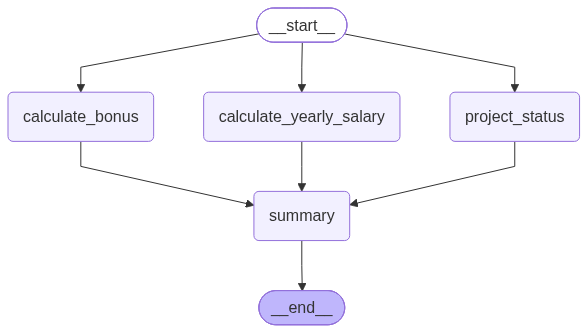

In [34]:
#compile graph
workflow = graph.compile()
workflow


In [35]:
intial_state = {
    "employee_name": "John Doe",
    "monthly_salary": 5000,
    "working_days": 22,
    "completed_project": 4
}



In [36]:
result=workflow.invoke(intial_state)

In [37]:
result

{'employee_name': 'John Doe',
 'monthly_salary': 5000,
 'working_days': 22,
 'completed_project': 4,
 'yearly_salary': 60000,
 'bonus_amount': 10000,
 'project_status': 'Good',
 'summary': 'Employee John Doe has a yearly salary of 60000, bonus amount of 10000, and project status is Good.'}